# Calidad Datos Movilidad Telefónica

### 1. Introducción

explicació


### 2. Carga de datos

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#### Información básica de cada conjunto

In [44]:
DATA_DIR = Path("../data/raw/telefonica")

# cargamos enero 2023 (PROVA)
month = "2023-01"
month_path = DATA_DIR / month

#tipos de datos para las columnas geográficas ya que tienen distintos valores
geo_dtypes = {
    "municipio_origen": "string",
    "municipio_destino": "string",
    "barrio_origen": "string",
    "barrio_destino": "string"
}

# Obtener las carpetas de todos los meses
carpetas = sorted([
    carpeta for carpeta in DATA_DIR.iterdir()
    if carpeta.is_dir()
])

print("Número de carpetas encontradas:", len(carpetas))



Número de carpetas encontradas: 32


Función para cargar cada archivo de cada mes

In [26]:
def cargar_datos(mes):
    carpeta = DATA_DIR / mes

    m1 = pd.read_csv(
        carpeta / f"movilidad_barrios_{mes}_origen.csv",
        dtype=geo_dtypes
    )

    m2 = pd.read_csv(
        carpeta / f"movilidad_municipios_{mes}_origen.csv",
        dtype=geo_dtypes
    )

    m3 = pd.read_csv(
        carpeta / f"movilidad_mun_barrios_{mes}_origen.csv",
        dtype=geo_dtypes
    )

    # Convertir fechas
    for df in [m1, m2, m3]:
        df["day"] = pd.to_datetime(df["day"], errors="coerce")

    return m1, m2, m3

In [30]:
def validar_calidad(df):
    return {
        "Registros": len(df),
        "Nulos": int(df.isnull().sum().sum()),
        "Duplicados": int(df.duplicated().sum())
    }

In [37]:
def validar_temporal(df, mes):

    # Fechas esperadas para el mes
    fechas_esperadas = pd.date_range(
        start=f"{mes}-01",
        end=pd.Timestamp(f"{mes}-01") + pd.offsets.MonthEnd(0)
    )

    # Fechas presentes
    fechas_presentes = pd.DatetimeIndex(df["day"].dropna().unique())
    fechas_faltantes = fechas_esperadas.difference(fechas_presentes)

    # Correspondencia entre números y días de la semana
    dias_semana = {
        0: "Lunes",
        1: "Martes",
        2: "Miércoles",
        3: "Jueves",
        4: "Viernes",
        5: "Sábado",
        6: "Domingo"
    }

    # Comprobar coherencia del día de la semana
    dia_real = df["day"].dt.day_of_week.map(dias_semana)
    errores_dia = (
        dia_real != df["day_of_week"].str.strip().str.title()
    ).sum()

    # Comprobar coherencia del mes
    errores_mes = (df["day"].dt.month != df["month"]).sum()

    # Comprobar fechas fuera del mes esperado
    fechas_fuera = (
        df["day"].notna() &
        ~df["day"].between(fechas_esperadas.min(), fechas_esperadas.max())
    ).sum()

    return {
        "Días esperados": len(fechas_esperadas),
        "Días presentes": len(fechas_presentes.intersection(fechas_esperadas)),
        "Días faltantes": len(fechas_faltantes),
        "Fechas inválidas": int(df["day"].isna().sum()),
        "Fechas fuera del mes": int(fechas_fuera),
        "Errores día semana": int(errores_dia),
        "Errores mes": int(errores_mes)
    }

In [39]:
def validar_geografia(df, dataset):

    BCN = "08019"

    # 1. Validar relaciones geográficas
    if dataset == "M1":
        errores_relaciones = (
            (df["municipio_origen"] != BCN) |
            (df["municipio_destino"] != BCN)
        ).sum()

    elif dataset == "M2":
        errores_relaciones = (
            df["municipio_origen"] == df["municipio_destino"]
        ).sum()

    elif dataset == "M3":
        origen_bcn = df["municipio_origen"] == BCN
        destino_bcn = df["municipio_destino"] == BCN
        errores_relaciones = (origen_bcn == destino_bcn).sum()

    else:
        raise ValueError("Dataset desconocido")

    # 2. Validar códigos de barrio
    errores_barrios = 0

    if dataset == "M1":
        errores_barrios = (
            (df["barrio_origen"] == "-") |
            (df["barrio_destino"] == "-")
        ).sum()

    elif dataset == "M3":
        errores_barrios = (
            ((df["municipio_origen"] == BCN) & (df["barrio_origen"] == "-")) |
            ((df["municipio_origen"] != BCN) & (df["barrio_origen"] != "-")) |
            ((df["municipio_destino"] == BCN) & (df["barrio_destino"] == "-")) |
            ((df["municipio_destino"] != BCN) & (df["barrio_destino"] != "-"))
        ).sum()

    # 3. Comprobar correspondencia entre códigos y nombres
    columnas = [
        ("municipio_origen", "municipio_origen_name"),
        ("municipio_destino", "municipio_destino_name")
    ]

    if dataset != "M2":
        columnas += [
            ("barrio_origen", "barrio_origen_name"),
            ("barrio_destino", "barrio_destino_name")
        ]

    errores_nombres = 0

    for codigo, nombre in columnas:
        errores_nombres += (
            df.groupby(codigo)[nombre].nunique() > 1
        ).sum()

    return {
        "Errores relaciones": int(errores_relaciones),
        "Errores barrios": int(errores_barrios),
        "Inconsistencias código-nombre": int(errores_nombres)
    }

In [41]:
def validar_viajes(df):

    negativos = (df["viajes"] < 0).sum()

    inferiores_15 = (
        (df["viajes"] > 0) & (df["viajes"] < 15)
    ).sum()

    return {
        "Viajes negativos": int(negativos),
        "Viajes entre 1 y 14": int(inferiores_15)
    }

In [31]:
# Cargar los datos de enero de 2023
m1, m2, m3 = cargar_datos("2023-01")

print("M1 - Barrios:", m1.shape)
print("M2 - Municipios:", m2.shape)
print("M3 - Municipios-Barrios:", m3.shape)

M1 - Barrios: (526810, 13)
M2 - Municipios: (1921078, 9)
M3 - Municipios-Barrios: (2641454, 13)


In [32]:
#columnas por dataset y tipo de dato
for name, df in {"M1": m1, "M2": m2, "M3": m3}.items():
    print(f"\n{'='*15} {name} {'='*15}")
    print(df.dtypes)


=============== M1 ===============
day                       datetime64[us]
day_of_week                          str
month                              int64
origen                               str
municipio_origen                  string
municipio_origen_name                str
barrio_origen                     string
barrio_origen_name                   str
municipio_destino                 string
municipio_destino_name               str
barrio_destino                    string
barrio_destino_name                  str
viajes                             int64
dtype: object

=============== M2 ===============
day                       datetime64[us]
day_of_week                          str
month                              int64
origen                               str
municipio_origen                  string
municipio_origen_name                str
municipio_destino                 string
municipio_destino_name               str
viajes                             int64
dtype: objec

Como vemos que el tipo de dato de la columna "day" es texto, lo cambiamos a tipo fecha

In [33]:
for df in [m1, m2, m3]:
    df["day"] = pd.to_datetime(df["day"], errors="coerce")

#comprobación del cambio
for name, df in {"M1": m1, "M2": m2, "M3": m3}.items():
    print(f"{name}:")
    print("Tipo:", df["day"].dtype)
    print("Primera fecha:", df["day"].min())
    print("Última fecha:", df["day"].max())
    print("Fechas inválidas:", df["day"].isna().sum())
    print()

M1:
Tipo: datetime64[us]
Primera fecha: 2023-01-01 00:00:00
Última fecha: 2023-01-31 00:00:00
Fechas inválidas: 0

M2:
Tipo: datetime64[us]
Primera fecha: 2023-01-01 00:00:00
Última fecha: 2023-01-31 00:00:00
Fechas inválidas: 0

M3:
Tipo: datetime64[us]
Primera fecha: 2023-01-01 00:00:00
Última fecha: 2023-01-31 00:00:00
Fechas inválidas: 0



#### Detección de nulos

In [34]:
for nombre, df in {"M1": m1, "M2": m2, "M3": m3}.items():
    print(f"{nombre}: {validar_calidad(df)}")

M1: {'Registros': 526810, 'Nulos': 0, 'Duplicados': 0}
M2: {'Registros': 1921078, 'Nulos': 0, 'Duplicados': 0}
M3: {'Registros': 2641454, 'Nulos': 0, 'Duplicados': 728722}


Vemos que no hay nulos en ninguna columna de ningun dataset pero hay una inconsistencia en M3 con los duplicados

#### Detectar registros duplicados

Podemos ver que 728.722 registros de 2.641.454 son duplicados. Esto es el 27,6% del dataset. Es un porcentaje elevado.

Una posible causa es el valor 0 como respuesta de privacidad. Vamos a comprobar si los duplicados tienen viajes = 0 o no.

In [8]:
duplicados = m3[m3.duplicated()]

print("Duplicados totales:", len(duplicados))
print("Duplicados con 0 viajes y %: ", (duplicados["viajes"]==0).sum(), " - ", round((duplicados["viajes"]==0).sum()/len(duplicados)*100, 2), "%")
print("Duplicados con viajes > 0 y %: ", (duplicados["viajes"]>0).sum(), " - ", round((duplicados["viajes"]>0).sum()/len(duplicados)*100, 2), "%")

Duplicados totales: 728722
Duplicados con 0 viajes y %:  718859  -  98.65 %
Duplicados con viajes > 0 y %:  9863  -  1.35 %


Esto sugiere una posible relación entre los duplicados y los valores censurados por privacidad.

Vamos a ver si los duplicados con viajes > 0 siguen algun patrón.

In [9]:
duplicados_positivos = duplicados[duplicados["viajes"]>0]
duplicados_positivos["viajes"].describe()

count    9863.000000
mean       32.379499
std        33.256021
min        15.000000
25%        18.000000
50%        23.000000
75%        35.000000
max       980.000000
Name: viajes, dtype: float64

La mayoria de los duplicados positivos representan flujos pequeños. El 50% tiene 23 viajes o menos, y el 75% tiene 35 viajes o menos. No obstante, el maximo es de 980 viajes

Por lo tanto, antes de decidir que hacer, miraremos la frecuencia de repetición de un registro

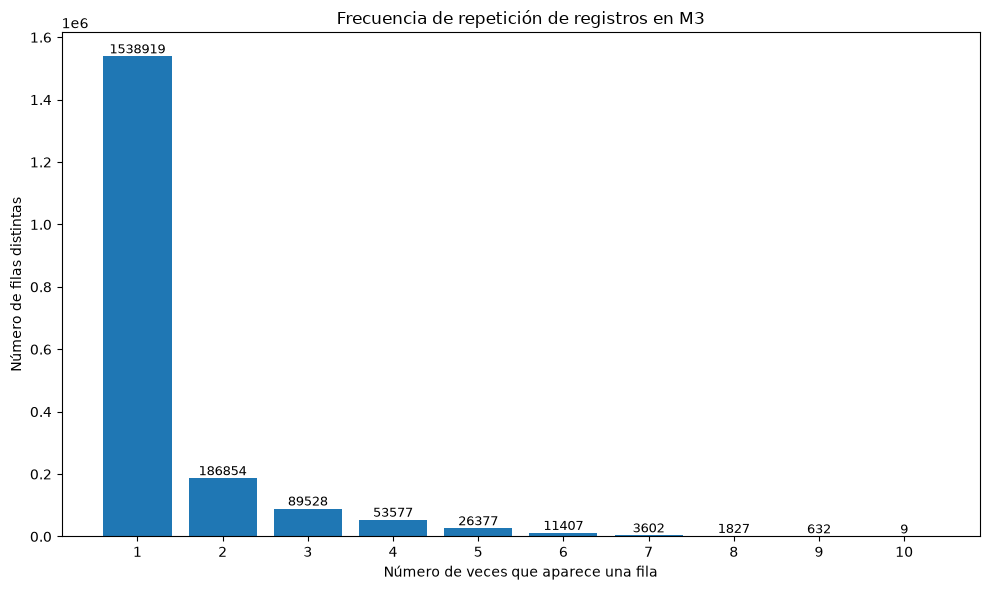

In [11]:
frecuencias = m3.value_counts()
repeticiones = frecuencias.value_counts().sort_index()

plt.figure(figsize=(10, 6))
bars = plt.bar(repeticiones.index, repeticiones.values)

plt.xlabel("Número de veces que aparece una fila")
plt.ylabel("Número de filas distintas")
plt.title("Frecuencia de repetición de registros en M3")
plt.xticks(repeticiones.index)

# Etiquetas con el valor exacto encima de cada barra
for bar in bars:
    altura = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        altura,
        f"{int(altura)}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

Vemos que la mayoria de registros de M3 son únicos, pero existen registros que se repiten hasta 10 veces. Por lo tantom la duplicación no es un fenomeno aislado.

Vamos a analizar las repeticiones según el número de viajes.

tipo_viajes,0 viajes,Viajes positivos,Total,% con 0 viajes
repeticiones,,,,
1,"969,060","569,859","1,538,919",62.97%
2,"177,435","9,419","186,854",94.96%
3,"89,315",213,"89,528",99.76%
4,"53,571",6,"53,577",99.99%
5,"26,377",0,"26,377",100.00%
6,"11,407",0,"11,407",100.00%
7,"3,602",0,"3,602",100.00%
8,"1,827",0,"1,827",100.00%
9,632,0,632,100.00%


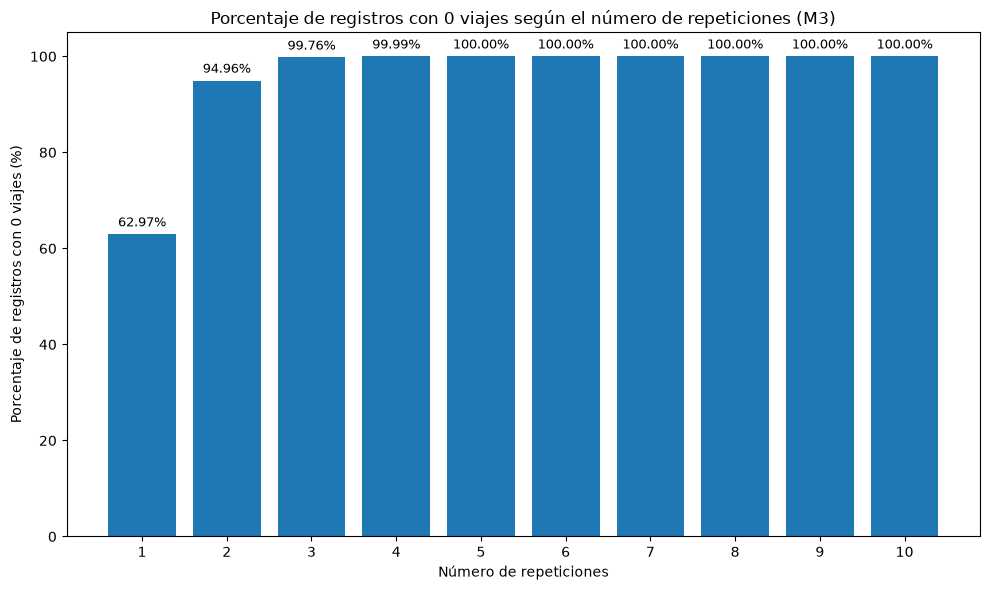

In [12]:
#contamos cuantas veces aparece cada fila distinta
frecuencias = m3.value_counts().reset_index(name="repeticiones")

#clasificamos segun el numero de viajes
frecuencias["tipo_viajes"] = np.where(frecuencias["viajes"]==0, "0 viajes", "Viajes positivos")

#contamos cuantos registros distintos por frecuencia y tipo
tabla = pd.crosstab(
    frecuencias["repeticiones"],
    frecuencias["tipo_viajes"]
)

tabla_resumen = tabla.copy()

tabla_resumen["Total"] = tabla_resumen.sum(axis=1)

tabla_resumen["% con 0 viajes"] = (
    tabla_resumen["0 viajes"] / tabla_resumen["Total"] * 100
)

display(
    tabla_resumen.style
    .format({
        "0 viajes": "{:,.0f}",
        "Viajes positivos": "{:,.0f}",
        "Total": "{:,.0f}",
        "% con 0 viajes": "{:.2f}%"
    })
    .set_caption("Distribución de registros de M3 según frecuencia de repetición")
)

plt.figure(figsize=(10, 6))
bars = plt.bar(
    tabla_resumen.index.astype(str),
    tabla_resumen["% con 0 viajes"]
)

plt.title("Porcentaje de registros con 0 viajes según el número de repeticiones (M3)")
plt.xlabel("Número de repeticiones")
plt.ylabel("Porcentaje de registros con 0 viajes (%)")
plt.ylim(0, 105)

# Etiquetas de datos
for bar in bars:
    altura = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        altura + 1,
        f"{altura:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

Vemos que hay una asociación fuerte entre la frecuencia de repetición y los valores 0. Nuestra hipotesi es que la anonimización sea la causa de los duplicados.

En el dataset M3 se han identificado 728.722 registros duplicados exactos en enero de 2023 (27,59 % del total), concentrados principalmente en observaciones con cero viajes. El comportamiento también se observa en febrero. Dado que la documentación del proveedor no especifica el tratamiento de estas repeticiones, se mantienen los datos originales y se pospone la eliminación hasta verificar su significado.

#### Validación consistencia temporal

Comprobar cobertura de dias

In [38]:
resultados_temporales = {
    nombre: validar_temporal(df, "2023-01")
    for nombre, df in {"M1": m1, "M2": m2, "M3": m3}.items()
}

tabla_temporal = pd.DataFrame(resultados_temporales).T

display(tabla_temporal)

,Días esperados,Días presentes,Días faltantes,Fechas inválidas,Fechas fuera del mes,Errores día semana,Errores mes
M1,31,31,0,0,0,0,0
M2,31,31,0,0,0,0,0
M3,31,31,0,0,0,0,0


La validación temporal de enero de 2023 confirma una cobertura completa de los 31 días en M1, M2 y M3. No se identifican fechas inválidas ni inconsistencias entre las fechas, los días de la semana y los meses registrados.

#### Validación geografica

Queremos comprobar que los desplazamientos respetan la estructura geografica definida por Telefónica

In [40]:
resultados_geograficos = {
    nombre: validar_geografia(df, nombre)
    for nombre, df in {"M1": m1, "M2": m2, "M3": m3}.items()
}

tabla_geografica = pd.DataFrame(resultados_geograficos).T

display(tabla_geografica)

,Errores relaciones,Errores barrios,Inconsistencias código-nombre
M1,0,0,0
M2,0,0,0
M3,0,0,0


La validación geográfica de los datasets M1, M2 y M3 correspondientes a enero de 2023 no ha detectado inconsistencias. Las relaciones origen-destino respetan las restricciones geográficas definidas por Telefónica, los códigos de barrio aparecen donde corresponde y no se han encontrado códigos asociados a distintos nombres dentro de las comprobaciones realizadas.

Por tanto, los datos presentan una estructura geográfica coherente. No obstante, queda pendiente contrastar los identificadores con fuentes geográficas oficiales y comprobar su consistencia entre los diferentes meses.

#### Validación de la variable "viajes"


Según la documentación oficial de Smart Steps, los desplazamientos inferiores a 15 se representan como cero por motivos de privacidad. 

En consecuencia, los valores observados de la variable `viajes` deberían pertenecer al siguiente conjunto:


$$
V \in \{0\} \cup \{15,16,17,\ldots\}
$$


Por tanto, se verificará que no existan:

- valores negativos;
- valores positivos inferiores a 15.

In [43]:
resultados_viajes = {
    nombre: validar_viajes(df)
    for nombre, df in {"M1": m1, "M2": m2, "M3": m3}.items()
}

tabla_viajes = pd.DataFrame(resultados_viajes).T

display(tabla_viajes)

,Viajes negativos,Viajes entre 1 y 14
M1,0,0
M2,0,0
M3,0,0


La validación de la variable `viajes` en los datasets M1, M2 y M3 de enero de 2023 no ha detectado valores negativos ni valores positivos inferiores a 15. Por tanto, los valores publicados cumplen las restricciones establecidas en la documentación de Smart Steps.

Los registros con cero viajes se conservarán, ya que pueden representar estimaciones inferiores a 15 desplazamientos por motivos de privacidad. Esta limitación deberá tenerse en cuenta en el posterior análisis estadístico.

### Validación de todo el dataset

In [45]:
resultados = []

for carpeta in carpetas:
    mes = carpeta.name
    print(f"Procesando {mes}...")

    # Cargar los tres datasets del mes
    m1_mes, m2_mes, m3_mes = cargar_datos(mes)

    # Aplicar las validaciones a cada dataset
    for nombre, df in {
        "M1": m1_mes,
        "M2": m2_mes,
        "M3": m3_mes
    }.items():

        resultado = {
            "Mes": mes,
            "Dataset": nombre,
            **validar_calidad(df),
            **validar_temporal(df, mes),
            **validar_geografia(df, nombre),
            **validar_viajes(df)
        }

        resultados.append(resultado)

    # Liberar las referencias a los datasets del mes
    del m1_mes, m2_mes, m3_mes

# Crear la tabla general de calidad
tabla_calidad_global = pd.DataFrame(resultados)

display(tabla_calidad_global.head(9))

Procesando 2023-01...
Procesando 2023-02...
Procesando 2023-03...
Procesando 2023-04...
Procesando 2023-05...
Procesando 2023-06...
Procesando 2023-07...
Procesando 2023-08...
Procesando 2023-09...
Procesando 2023-10...
Procesando 2023-11...
Procesando 2023-12...
Procesando 2024-01...
Procesando 2024-02...
Procesando 2024-03...
Procesando 2024-04...
Procesando 2024-05...
Procesando 2024-06...
Procesando 2024-07...
Procesando 2024-08...
Procesando 2024-09...
Procesando 2024-10...
Procesando 2024-11...
Procesando 2024-12...
Procesando 2025-01...
Procesando 2025-02...
Procesando 2025-03...
Procesando 2025-04...
Procesando 2025-05...
Procesando 2025-06...
Procesando 2025-07...
Procesando 2025-08...


,Mes,Dataset,Registros,Nulos,Duplicados,Días esperados,Días presentes,Días faltantes,Fechas inválidas,Fechas fuera del mes,Errores día semana,Errores mes,Errores relaciones,Errores barrios,Inconsistencias código-nombre,Viajes negativos,Viajes entre 1 y 14
0,2023-01,M1,526810,0,0,31,31,0,0,0,0,0,0,0,0,0,0
1,2023-01,M2,1921078,0,0,31,31,0,0,0,0,0,0,0,0,0,0
2,2023-01,M3,2641454,0,728722,31,31,0,0,0,0,0,0,0,0,0,0
3,2023-02,M1,478729,0,0,28,28,0,0,0,0,0,0,0,0,0,0
4,2023-02,M2,1786595,0,0,28,28,0,0,0,0,0,0,0,0,0,0
5,2023-02,M3,2420389,0,657625,28,28,0,0,0,0,0,0,0,0,0,0
6,2023-03,M1,535645,0,0,31,31,0,0,0,0,0,0,0,0,0,0
7,2023-03,M2,2025570,0,0,31,31,0,0,0,0,0,0,0,0,0,0
8,2023-03,M3,2742841,0,736237,31,31,0,0,0,0,0,0,0,0,0,0


In [ ]:
#resumen de todos los meses por dataset (m1, m2, m3)
resumen_global = tabla_calidad_global.groupby("Dataset").sum(numeric_only=True)

#calculamos % de duplicados
resumen_global["% Duplicados"] = (
    resumen_global["Duplicados"] / resumen_global["Registros"] * 100
)

#mostramos el resumen 
columnas = [
    "Registros",
    "Nulos",
    "Duplicados",
    "% Duplicados",
    "Días faltantes",
    "Fechas inválidas",
    "Fechas fuera del mes",
    "Errores día semana",
    "Errores mes",
    "Errores relaciones",
    "Errores barrios",
    "Inconsistencias código-nombre",
    "Viajes negativos",
    "Viajes entre 1 y 14"
]

display(
    resumen_global[columnas].style.format({
        col: "{:,.0f}" for col in columnas if col != "% Duplicados"
    } | {"% Duplicados": "{:.2f}%"})
)

,Registros,Nulos,Duplicados,% Duplicados,Días faltantes,Fechas inválidas,Fechas fuera del mes,Errores día semana,Errores mes,Errores relaciones,Errores barrios,Inconsistencias código-nombre,Viajes negativos,Viajes entre 1 y 14
Dataset,,,,,,,,,,,,,,
M1,"16,560,949",0,0,0.00%,3,0,0,0,0,0,0,0,0,0
M2,"64,880,151",0,0,0.00%,3,0,0,0,0,0,0,0,0,0
M3,"85,823,522",0,"23,790,018",27.72%,3,0,0,0,0,0,0,0,0,0


Podemos extraer tres conclusiones:

Primera: la calidad de la estructura de los datos es buena. No hemos encontrado valores nulos, fechas inválidas, incoherencias geográficas ni valores de viajes que incumplan las reglas de Telefónica.

Segunda: los duplicados de M3 se repiten a lo largo del histórico. Tenemos 23.790.018 filas duplicadas, lo que representa el 27,72 % de M3. 

Tercera, y especialmente importante: faltan tres días en cada dataset. Hasta ahora habíamos comprobado enero de 2023, que estaba completo, pero la validación global ha detectado una ausencia temporal.

In [48]:
# Meses donde hemos detectado días faltantes
meses_incompletos = ["2024-02", "2025-04", "2025-05"]

for mes in meses_incompletos:

    m1_mes, m2_mes, m3_mes = cargar_datos(mes)

    fechas_esperadas = pd.date_range(
        start=f"{mes}-01",
        end=pd.Timestamp(f"{mes}-01") + pd.offsets.MonthEnd(0)
    )

    for nombre, df in {"M1": m1_mes, "M2": m2_mes, "M3": m3_mes}.items():

        fechas_presentes = pd.DatetimeIndex(df["day"].dropna().unique())
        fechas_faltantes = fechas_esperadas.difference(fechas_presentes)

        print(f"{mes} - {nombre}: {fechas_faltantes.strftime('%Y-%m-%d').tolist()}")

    del m1_mes, m2_mes, m3_mes

2024-02 - M1: ['2024-02-11']
2024-02 - M2: ['2024-02-11']
2024-02 - M3: ['2024-02-11']
2025-04 - M1: ['2025-04-13']
2025-04 - M2: ['2025-04-13']
2025-04 - M3: ['2025-04-13']
2025-05 - M1: ['2025-05-20']
2025-05 - M2: ['2025-05-20']
2025-05 - M3: ['2025-05-20']


La validación temporal del período enero de 2023 – agosto de 2025 ha identificado tres fechas sin registros: 11/02/2024, 13/04/2025 y 20/05/2025. Estas ausencias afectan simultáneamente a los datasets M1, M2 y M3.

La cobertura temporal global es del 99,69 %. No se han detectado fechas inválidas, registros fuera de su mes correspondiente ni inconsistencias entre las fechas y los días de la semana.

Los días ausentes se mantendrán como datos no disponibles, sin imputar valores, para evitar introducir distorsiones en el posterior análisis estadístico. En los cálculos de patrones habituales de movilidad se excluirán las fechas sin observaciones y se documentará el número de días de referencia disponibles.


### Evaluación del impacto de los duplicados en M3

Durante la validación de calidad se han identificado 23.790.018 registros duplicados exactos en M3, equivalentes al 27,72 % del total de registros del dataset.

Sin embargo, la mayoría de los duplicados corresponden a registros con `viajes = 0`, por lo que el porcentaje de filas duplicadas no representa necesariamente el impacto sobre el volumen total de viajes.

Para evaluar este impacto, se comparan dos versiones del dataset de enero de 2023:

- **Datos originales:** incluyen todos los registros proporcionados por Telefónica.
- **Datos sin duplicados:** conservan una única aparición de cada fila exactamente idéntica.

En primer lugar, calculamos el volumen total de viajes publicados en cada versión:

$$
V_{\text{original}} = \sum_{i=1}^{N} v_i
$$

$$
V_{\text{sin duplicados}} = \sum_{i=1}^{N'} v_i
$$

Donde:

- $v_i$ representa el número de viajes publicados en cada registro.
- $N$ es el número de registros originales.
- $N'$ es el número de registros después de eliminar los duplicados exactos.

A continuación, calculamos el porcentaje de reducción del volumen de viajes:

$$
R(\%) = \frac{V_{\text{original}} - V_{\text{sin duplicados}}}{V_{\text{original}}} \times 100
$$

Este indicador permite cuantificar cuánto cambia el volumen total de viajes publicados al eliminar los duplicados exactos.

**Consideración metodológica:** la eliminación de duplicados se realiza únicamente sobre una copia del dataset, conservando los datos originales. Esta comparación constituye un análisis de sensibilidad, ya que todavía no se ha confirmado con Telefónica si las repeticiones deben eliminarse.

Además, los resultados deben interpretarse teniendo en cuenta que los valores inferiores a 15 viajes se representan como cero por privacidad. Por tanto, las sumas corresponden a los viajes publicados y no necesariamente al volumen real completo de desplazamientos.


In [49]:
# Crear una copia de M3 sin duplicados exactos
m3_sin_duplicados = m3.drop_duplicates()

print("Registros originales:", len(m3))
print("Registros sin duplicados:", len(m3_sin_duplicados))
print("Registros eliminados:", len(m3) - len(m3_sin_duplicados))

# Comprobar cómo afecta al total de viajes publicados
viajes_originales = m3["viajes"].sum()
viajes_sin_duplicados = m3_sin_duplicados["viajes"].sum()

print("\nViajes originales:", f"{viajes_originales:,}")
print("Viajes sin duplicados:", f"{viajes_sin_duplicados:,}")

variacion = (
    (viajes_originales - viajes_sin_duplicados)
    / viajes_originales * 100
)

print("Reducción de viajes publicados:", f"{variacion:.2f}%")

Registros originales: 2641454
Registros sin duplicados: 1912732
Registros eliminados: 728722

Viajes originales: 33,258,586
Viajes sin duplicados: 32,939,227
Reducción de viajes publicados: 0.96%


La eliminación de duplicados exactos en M3 para enero de 2023 reduce el número de registros de 2.641.454 a 1.912.732, lo que representa una reducción del 27,59 %.

Sin embargo, el volumen total de viajes publicados disminuye únicamente un 0,96 %, pasando de 33.258.586 a 32.939.227 viajes. Esta diferencia se explica principalmente por la elevada proporción de registros duplicados con cero viajes.

Estos resultados indican que los duplicados tienen un impacto relativamente pequeño sobre el volumen agregado de viajes publicados, aunque podrían afectar de manera desigual a determinadas relaciones origen-destino.

Por tanto, la eliminación de duplicados se mantendrá como una hipótesis de tratamiento pendiente de validación con Telefónica. Se conservarán los archivos originales y se documentará esta decisión para evaluar su impacto en el posterior análisis estadístico.